In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist

from aspire.utils import gaussian_window, grid_2d, randn, trange
import tqdm
from overcrowding_utils import estimate_mean_naive, estimate_covar_naive, estimate_mean_ctfless, estimate_covar_ctfless, conv_diag, make_p_eff, estimate_psd
from utils_cwf_fast_batch import get_clean_mean_batch, get_clean_covar_batch, get_noise_var_batch
from scipy.sparse.linalg import LinearOperator, gmres
from scipy.signal import fftconvolve, oaconvolve
from aspire.source.micrograph import MicrographSimulation
from aspire.volume import Volume
from aspire.utils import Rotation, logging
from aspire.source import ArrayImageSource, Simulation
from itertools import permutations
import time

logging.setConsoleLoggingLevel("WARNING")

psd_size = 48
dtype = np.float64

In [2]:
x = np.linspace(-psd_size//2, psd_size//2, psd_size, endpoint = False) / (psd_size//4)
xx, yy, zz = np.meshgrid(x, x, x)
rr = np.sqrt(xx**2 + yy**2 + zz**2)
vol = np.exp(-2.5 * rr**3)

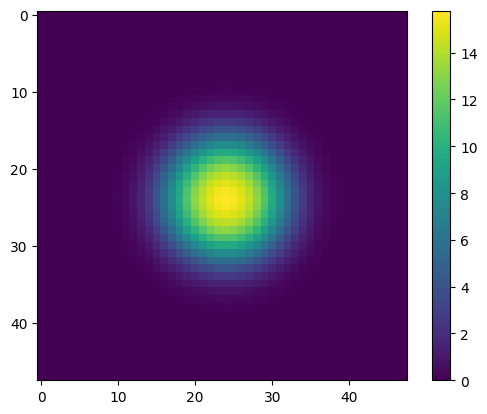

In [3]:
plt.imshow(np.sum(vol, axis = 0))
plt.colorbar()

102.19885804292184
10501.259303012404


100%|██████████| 3/3 [00:00<00:00, 155.52it/s]


Time took for gmres: 0.776381774743398 min
101.30408951381325
10291.714031092188


100%|██████████| 6/6 [00:00<00:00, 160.42it/s]


Time took for gmres: 0.7623239239056905 min
100.3791668755326
10136.355606797333


...

Time took for gmres: 0.7697869499524435 min
100.31143686211728
10097.73644186512


100%|██████████| 20/20 [00:00<00:00, 149.12it/s]


Time took for gmres: 0.7810530702273051 min
100.43503686117705
10124.084293389978


100%|██████████| 41/41 [00:00<00:00, 65.71it/s]


Time took for gmres: 0.7767266670862834 min


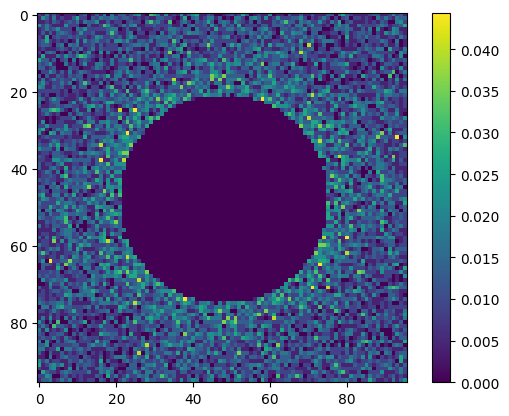

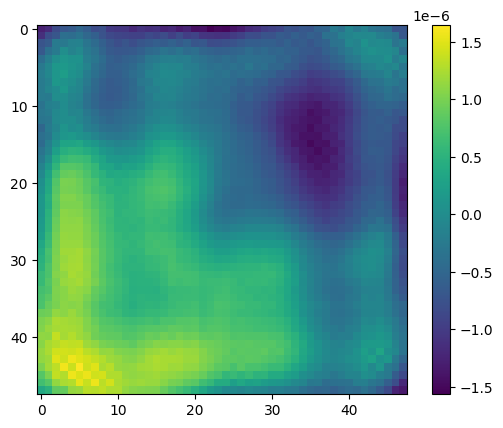

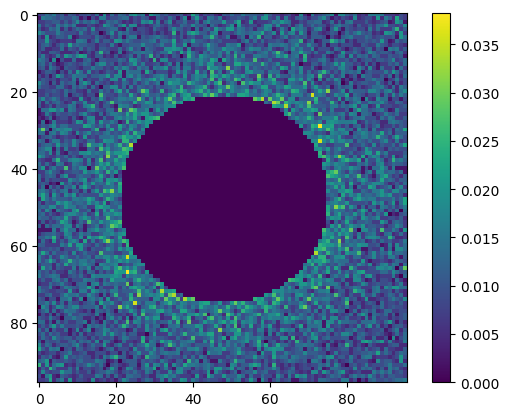

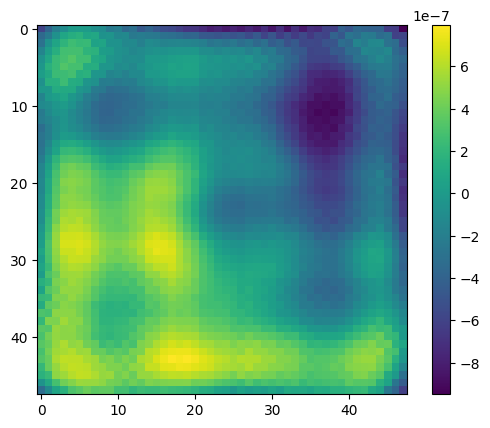

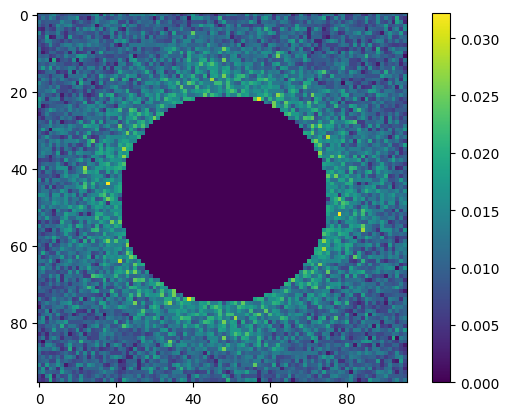

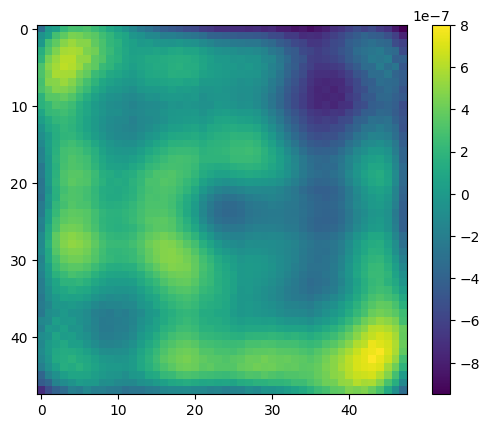

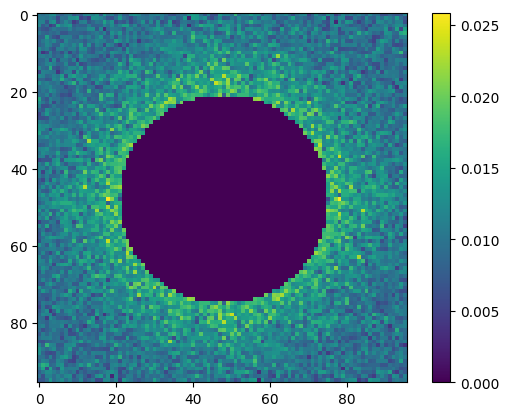

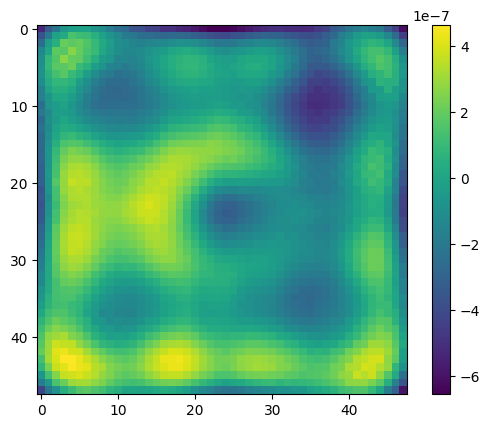

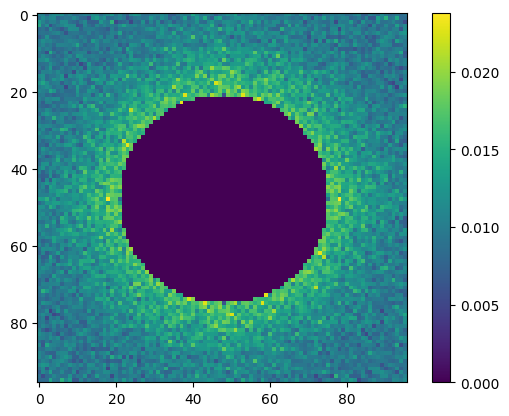

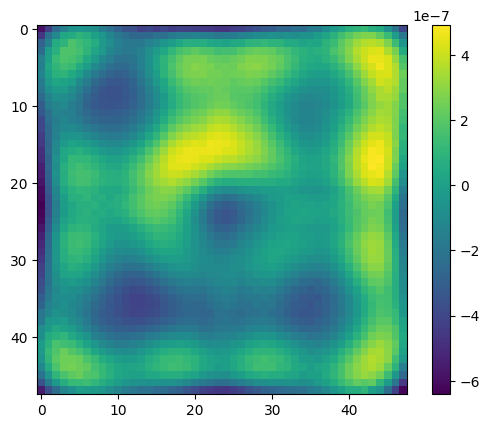

<Figure size 640x480 with 0 Axes>

In [4]:
nums_micrographs = [50, 100, 200, 400, 800]
micrograph_size = psd_size * 10 

mean_errs = []
covar_errs = []
rng = np.random.default_rng(seed=1234)

for num_micrographs in nums_micrographs:
    particles_per_micrograph = rng.integers(80, 121, num_micrographs)
    angles = Rotation.generate_random_rotations(np.sum(particles_per_micrograph), seed = 1234).angles
    alpha_numerator = np.sum(particles_per_micrograph * (particles_per_micrograph - 1))
    beta_numerator = np.sum(particles_per_micrograph * (particles_per_micrograph - 1) * (particles_per_micrograph - 2))
    alpha = alpha_numerator / np.sum(particles_per_micrograph)
    beta = beta_numerator / np.sum(particles_per_micrograph)
    print(alpha)
    print(beta)
    pixel_size = 1.34 * 360 / psd_size
    split_angles = np.split(angles, np.cumsum(particles_per_micrograph)[:-1])
    micro_srcs = []
    for i in range(num_micrographs):
        micro_srcs.append(MicrographSimulation(
                micrograph_size = micrograph_size,
                micrograph_count = 1,
                particles_per_micrograph=particles_per_micrograph[i],
                particle_amplitudes=psd_size,
                projection_angles = split_angles[i], 
                volume=Volume(vol),
                interparticle_distance = 9 * psd_size / 16,
                pixel_size = pixel_size,
                seed = 1234*i,
        )
                         )
    
    uncrowded_src = Simulation(
        L=psd_size,
        n=np.sum(particles_per_micrograph),
        vols=Volume(vol),
        amplitudes=psd_size,
        dtype=dtype,
        offsets = 0,
        pixel_size = pixel_size,
        angles = angles
    )
    
    img_array = []
    for i in range(num_micrographs):
        micrograph = micro_srcs[i].images[0].asnumpy()[0]
        for center in micro_srcs[i].centers[0]:
            x, y = center
            if x - psd_size//2 >= 0 and x+psd_size//2 < micrograph_size and y - psd_size//2 >= 0 and y + psd_size//2 < micrograph_size:
                img_array.append(micrograph[x-psd_size//2:x+psd_size//2, y-psd_size//2:y+psd_size//2])
    img_array = np.array(img_array)
    crowded_src = ArrayImageSource(img_array, pixel_size = pixel_size)
    
    centers = [micro_srcs[i].centers[0].astype(np.float64) for i in range(num_micrographs)]
    
    uncrowded_mean = estimate_mean_ctfless(uncrowded_src).real
    
    real_covar = estimate_covar_ctfless(crowded_src)
    
    est_uncrowded_outer_product = uncrowded_mean.reshape(-1, 1) @ uncrowded_mean.reshape(1, -1)
    uncrowded_covar = estimate_covar_ctfless(uncrowded_src) 
    
    distances = []
    for i in range(num_micrographs):
        distances.append(pdist(centers[i]))
    distances = np.concatenate(distances) / psd_size
    
    raw_distances = []
    for i in range(num_micrographs):
        comp = centers[i][None, :, :] - centers[i][:, None, :]
        to_add = comp[~np.eye(len(centers[i]), dtype=bool)] / psd_size
        to_add = to_add[((np.abs(to_add[:, 0]) <= np.sqrt(2)) & (np.abs(to_add[:, 1]) <= np.sqrt(2)))]
        raw_distances.append(to_add)
    raw_distances = np.concatenate(raw_distances)
    
    
    raw_triples = []
    for m in range(num_micrographs):
        pts = centers[m]
        N = len(pts)
        for i in range(N):
            V = pts - pts[i]
            V = V[np.linalg.norm(V, axis = 1) > 1e-12]
    
            V1 = np.broadcast_to(V[:, None, :], (N-1, N-1, 2))
            V2 = np.broadcast_to(V[None, :, :], (N-1, N-1, 2))
            
            pair_tensor = np.concatenate((V1, V2), axis=-1)
            pair_mask = ~np.eye(len(V), dtype=bool)
            to_add = pair_tensor[pair_mask] / psd_size
            to_add = to_add[((np.abs(to_add[:, 0]) <= np.sqrt(2)) & (np.abs(to_add[:, 1]) <= np.sqrt(2)) & (np.abs(to_add[:, 2]) <= np.sqrt(2)) & (np.abs(to_add[:, 3]) <= np.sqrt(2)))]
            raw_triples.append(to_add)
    raw_triples = np.concatenate(raw_triples, axis=0)
    
    raw_triples2 = []
    for m in range(num_micrographs):
        pts = centers[m]
        N = len(pts)
        for i in range(N):
            V = pts - pts[i]
            V = V[np.linalg.norm(V, axis = 1) > 1e-12]
    
            V1 = np.broadcast_to(V[:, None, :], (N-1, N-1, 2))
            V2 = np.broadcast_to(V[None, :, :], (N-1, N-1, 2))
            
            pair_tensor = np.concatenate((V1, V2), axis=-1)
            pair_mask = ~np.eye(len(V), dtype=bool)
            to_add = pair_tensor[pair_mask] / psd_size
            raw_triples2.append(to_add)
    raw_triples2 = np.concatenate(raw_triples2, axis=0)
    
    H, edges = np.histogramdd(
        raw_distances,
        bins=(2 * psd_size, 2 * psd_size),
        range=[[-1, 1 - 1/(psd_size)], [-1, 1 - 1/(psd_size)]]
    )
    
    p_eff = H / alpha_numerator * psd_size**2
    
    plt.imshow(p_eff)
    plt.colorbar()
    plt.figure()
    
    observed_mean = estimate_mean_ctfless(crowded_src)
    
    mean_coords = np.arange(psd_size) - psd_size // 2
    X, Y = np.meshgrid(mean_coords, mean_coords, indexing="ij")
    
    mean_indices = np.where(np.linalg.norm(np.array([X, Y]), axis = 0, ord =np.inf) <= psd_size//2)
    
    mean_len = len(mean_indices[0])
    
    def matvec_mean_binning(v):
        v_ = np.zeros((psd_size, psd_size), dtype = np.complex128)
        v_[mean_indices] = v.flatten()
        
        term_hi = alpha * fftconvolve(p_eff, v_, mode = "full")[psd_size:-psd_size+1,psd_size:-psd_size+1] / (psd_size)**2
        return (v_ + term_hi)[mean_indices]
        
    mean_A_binning = LinearOperator(
        shape=(mean_len, mean_len),
        matvec=matvec_mean_binning,
        dtype=np.float64,
    )
    
    remean_binning = np.zeros((psd_size, psd_size), dtype = np.complex128)
    soln_binning, info = gmres(mean_A_binning, observed_mean[mean_indices], rtol = 1e-6)
    remean_binning[mean_indices] = soln_binning
    plt.imshow(remean_binning.real - uncrowded_mean)
    plt.colorbar()
    plt.figure()
    
    mean_err = np.linalg.norm(remean_binning.real - uncrowded_mean) / np.linalg.norm(uncrowded_mean) * 100
    
    # COVAR
    
    crowded_covar = real_covar - (observed_mean.reshape(-1, 1) @ observed_mean.reshape(1, -1))
    
    crowded_covar = crowded_covar.reshape(psd_size, psd_size, psd_size, psd_size)
    real_covar = real_covar.reshape(psd_size, psd_size, psd_size, psd_size)
    
    mean_diff_binning = observed_mean - remean_binning
    term2_binning = (mean_diff_binning.reshape(-1, 1) @ remean_binning.reshape(1, -1)).reshape(psd_size, psd_size, psd_size, psd_size)
    term3_binning = (remean_binning.reshape(-1, 1) @ mean_diff_binning.reshape(1, -1)).reshape(psd_size, psd_size, psd_size, psd_size)
    
    diag_p_binning_hi = np.diag(p_eff.ravel()).reshape(2*psd_size, 2*psd_size, 2*psd_size, 2*psd_size)
    
    cut_scaling = 1 / beta_numerator
    
    H, _ = np.histogramdd(
        raw_triples,
        bins=(2 * psd_size, 2 * psd_size, 2 * psd_size, 2 * psd_size),
        range=[[-1, 1 - 1/(psd_size)], [-1, 1 - 1/(psd_size)], [-1, 1 - 1/(psd_size)], [-1, 1 - 1/(psd_size)]],
    )
    c_eff = H * cut_scaling * psd_size**4
    del H
    
    binning_outer_product = (remean_binning.reshape(-1, 1) @ remean_binning.reshape(1, -1)).reshape(psd_size, psd_size, psd_size, psd_size)
    
    tmp = oaconvolve(
        c_eff,
        remean_binning[:, :, None, None],
        mode="valid",
        axes=(0, 1),
    )[1:, 1:, :, :]
    
    term5_binning_hi = oaconvolve(
        tmp,
        remean_binning[None, None, :, :],
        mode="valid",
        axes=(2, 3),
    )[:, :, 1:, 1:]
    
    coords = np.arange(psd_size) - psd_size // 2
    X, Y, Z, ZZ = np.meshgrid(coords, coords, coords, coords, indexing="ij")
    indices = np.where(np.linalg.norm(np.array([X, Y, Z, ZZ]), axis = 0, ord = np.inf) <= psd_size//2)
    
    def matvec_covar_binning(v):
        X = np.zeros((psd_size, psd_size, psd_size, psd_size), dtype=v.dtype)
    
        X[indices] = v.flatten()
    
        cov_hi = X # we will just use an effective diag_p_binning_hi instead of explicitly repeating
    
        term4_hi = conv_diag(cov_hi, p_eff)
    
        term4_hi *= alpha / psd_size**2
        return v + term4_hi[indices] 
        
    A_covar_binning = LinearOperator(
        shape=(len(indices[0]), len(indices[0])),
        matvec=matvec_covar_binning,
        dtype=np.float64,
    )
    
    t0 = time.time()
    soln_binning, info = gmres(A_covar_binning, (real_covar - (term2_binning + term3_binning  + \
                        beta * term5_binning_hi / (psd_size)**4))[indices], rtol = 1e-6)
    print(f'Time took for gmres: {(time.time() - t0) / 60} min')
    recovar_binning = np.zeros((psd_size, psd_size, psd_size, psd_size), dtype=soln_binning.dtype)
    
    recovar_binning[indices] = soln_binning.flatten()
    
    true_outer_product = (uncrowded_mean.reshape(-1, 1) @ uncrowded_mean.reshape(1, -1)).reshape(uncrowded_covar.shape)
    crowded_outer_product = observed_mean.reshape(-1, 1) @ observed_mean.reshape(1, -1)
    covar_err = np.linalg.norm(recovar_binning.reshape(uncrowded_covar.shape) - uncrowded_covar - (est_uncrowded_outer_product - true_outer_product)) / np.linalg.norm(crowded_covar - crowded_outer_product.reshape(crowded_covar.shape)) * 100
    covar_errs.append(covar_err)
    mean_errs.append(mean_err)

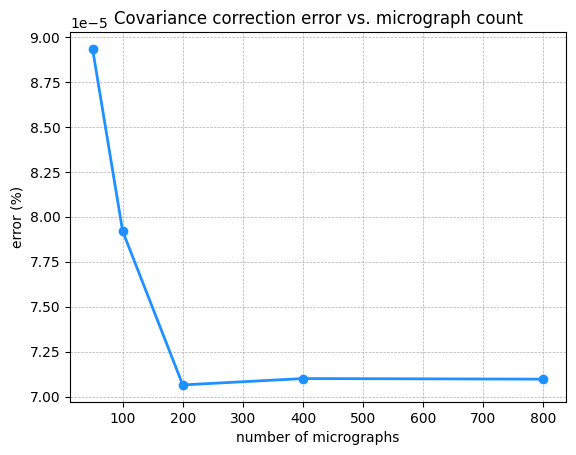

In [5]:
plt.plot(nums_micrographs, covar_errs, "-o",lw=2.0,c="dodgerblue", label="covariance")
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.title(f"Covariance correction error vs. micrograph count")
plt.ylabel("error (%)")
plt.xlabel("number of micrographs")
plt.savefig("final_overcrowding_paper_figs/res1/cov_vs_n.pdf", bbox_inches = "tight")

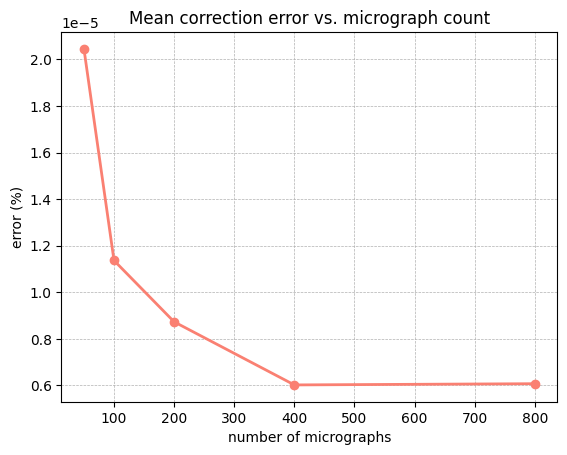

In [6]:
plt.plot(nums_micrographs, mean_errs, "-o",lw=2.0, c="salmon", label = "mean")
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.title(f"Mean correction error vs. micrograph count")
plt.ylabel("error (%)")
plt.xlabel("number of micrographs")
plt.savefig("final_overcrowding_paper_figs/res1/mean_vs_n.pdf", bbox_inches = "tight")

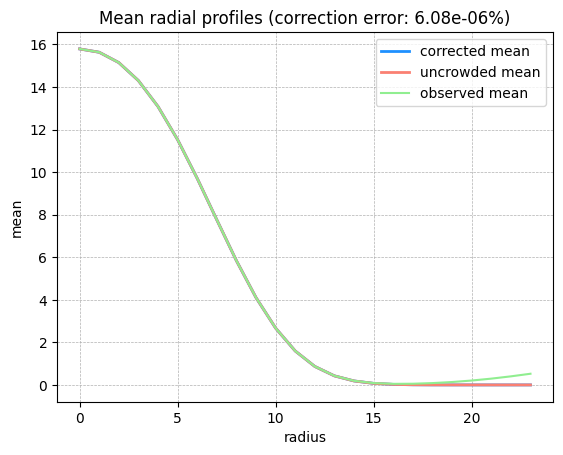

In [7]:
plt.plot(np.abs(remean_binning[psd_size//2, psd_size//2:]), lw=2.0,label = "corrected mean", color="dodgerblue")
plt.plot(np.abs(uncrowded_mean[psd_size//2, psd_size//2:]), lw=2.0, label = "uncrowded mean", color="salmon")
plt.plot(np.abs(observed_mean[psd_size//2, psd_size//2:]), label = "observed mean", color="lightgreen")
plt.grid(True, which='major', linestyle='--', linewidth=0.5)
plt.title(f"Mean radial profiles (correction error: {mean_err:.2e}%)")
plt.xlabel("radius")
plt.ylabel("mean")
plt.legend()
plt.savefig("final_overcrowding_paper_figs/res1/means.pdf",bbox_inches = "tight")

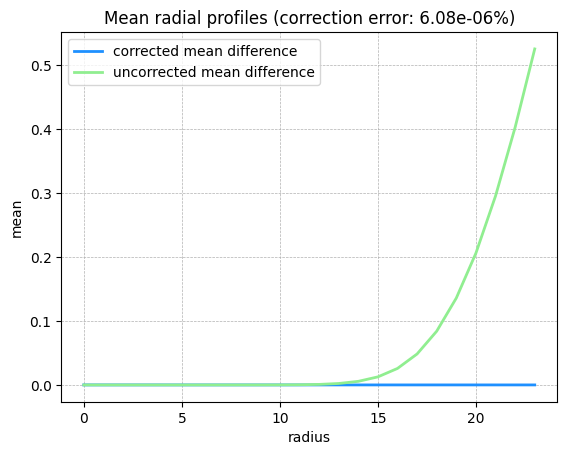

In [8]:
plt.plot(np.abs((remean_binning - uncrowded_mean)[psd_size//2, psd_size//2:]), lw=2.0,label = "corrected mean difference", color="dodgerblue")
plt.plot(np.abs((observed_mean - uncrowded_mean)[psd_size//2, psd_size//2:]), lw=2.0, label = "uncorrected mean difference", color="lightgreen")
plt.grid(True, which='major', linestyle='--', linewidth=0.5)
plt.title(f"Mean radial profiles (correction error: {mean_err:.2e}%)")
plt.xlabel("radius")
plt.ylabel("mean")
plt.legend()
plt.savefig("final_overcrowding_paper_figs/res1/mean_diff.pdf",bbox_inches = "tight")

In [9]:
def save_image(img, fname, cmap="gray"):
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(img, cmap=cmap)
    ax.set_axis_off()
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
    fig.savefig(fname, format="pdf", bbox_inches="tight", pad_inches=0)
    plt.close(fig)

micrograph = micro_srcs[0].images[0].asnumpy()[0]
save_image(micrograph, "final_overcrowding_paper_figs/res1/micrograph.pdf")

particles = crowded_src.images[:2].asnumpy()
save_image(particles[0], "final_overcrowding_paper_figs/res1/particle_1.pdf")
save_image(particles[1], "final_overcrowding_paper_figs/res1/particle_2.pdf")